# Comparative Customer Analysis

## Project Goal

This notebook builds on the exploratory data analysis by comparing customer characteristics and campaign outcomes across multiple variables.

Rather than examining variables independently, this analysis investigates how customer demographics, financial characteristics, and campaign interactions relate to term deposit subscription behavior.

These comparisons provide more meaningful business insights by identifying customer segments and campaign characteristics associated with higher or lower subscription rates.

In [36]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.ticker import StrMethodFormatter

# Load the dataset
df = pd.read_csv("../data/raw/bank-full.csv", sep=";")

# Display the first five rows
df.head()


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 1. Dataset Overview

Before comparing customer groups, verify the size and structure of the dataset.

In [37]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

df.info()

Rows: 45,211
Columns: 17
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


## 2. Overall Campaign Outcome

The target variable `y` indicates whether a customer subscribed to a term deposit after the marketing campaign.

Understanding the overall subscription rate provides a baseline for evaluating individual customer segments.

In [38]:
subscription_counts = df["y"].value_counts()
subscription_rates = df["y"].value_counts(normalize=True) * 100

print("Subscription Counts:")
print(subscription_counts)

print("\nSubscription Rates:")
print(subscription_rates.round(2))

Subscription Counts:
y
no     39922
yes     5289
Name: count, dtype: int64

Subscription Rates:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


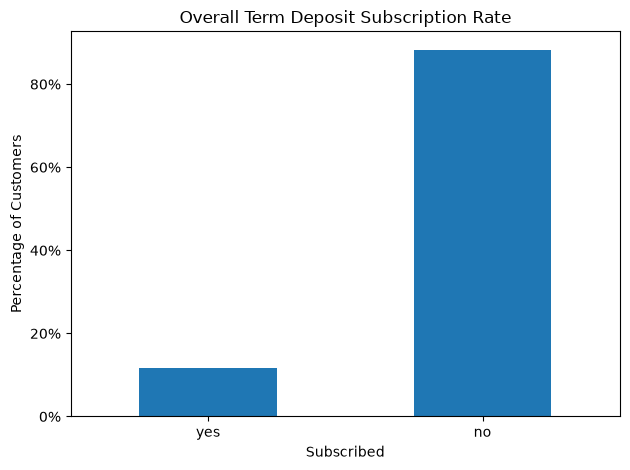

In [39]:
subscription_rates.sort_values().plot(kind="bar")

plt.title("Overall Term Deposit Subscription Rate")
plt.xlabel("Subscribed")
plt.ylabel("Percentage of Customers")
plt.gca().yaxis.set_major_formatter(PercentFormatter())
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Business Interpretation

The overall subscription rate establishes the baseline campaign response rate. Because substantially more customers did not subscribe than subscribed, the target variable is imbalanced.

This is important for later predictive modeling because accuracy alone may not provide an adequate measure of model performance. Metrics such as precision, recall, F1-score, and ROC-AUC should also be considered.

## 3. Subscription Rate by Job

Customer occupation may help identify segments that respond differently to marketing campaigns.

In [40]:
job_subscription = (
    df.groupby("job")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .sort_values(ascending=False)
)

job_subscription

job
student          28.678038
retired          22.791519
unemployed       15.502686
management       13.755551
admin.           12.202669
self-employed    11.842939
unknown          11.805556
technician       11.056996
services          8.883004
housemaid         8.790323
entrepreneur      8.271688
blue-collar       7.274969
Name: y, dtype: float64

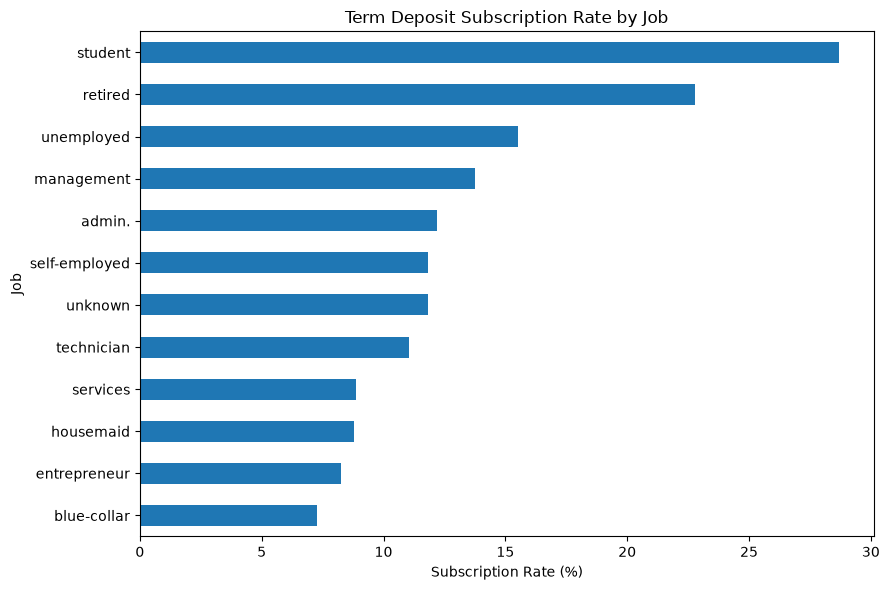

In [41]:
job_subscription.sort_values().plot(kind="barh", figsize=(9, 6))

plt.title("Term Deposit Subscription Rate by Job")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Job")
plt.tight_layout()
plt.show()

### Business Interpretation

Subscription rates vary across occupational groups, suggesting that customer occupation may contain useful information for customer segmentation.

However, response rate alone should not determine campaign targeting. Segment size, customer financial characteristics, and other variables should also be considered before making business recommendations.

## 4. Subscription Rate by Age Group

Individual ages can produce noisy comparisons, so customers are grouped into broader age ranges to make differences easier to interpret.

In [42]:
age_bins = [0, 29, 39, 49, 59, 69, 100]
age_labels = ["Under 30", "30-39", "40-49", "50-59", "60-69", "70+"]

df["age_group"] = pd.cut(
    df["age"],
    bins=age_bins,
    labels=age_labels
)

age_subscription = (
    df.groupby("age_group", observed=False)["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
)

age_subscription

age_group
Under 30    17.599090
30-39       10.575488
40-49        9.120549
50-59        9.334126
60-69       29.674797
70+         42.418773
Name: y, dtype: float64

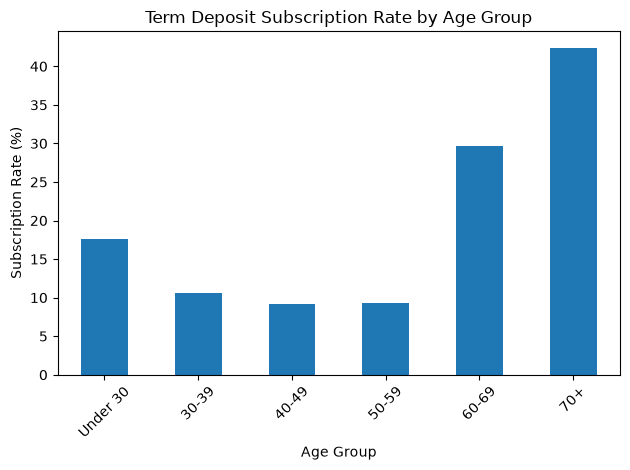

In [43]:
age_subscription.plot(kind="bar")

plt.title("Term Deposit Subscription Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Business Interpretation

Comparing age groups allows the bank to determine whether campaign response differs across stages of the customer lifecycle.

Age should not be interpreted independently, however. Differences between age groups may also reflect employment status, account balances, housing obligations, or other customer characteristics.

## 5. Account Balance and Subscription

Account balance provides a basic measure of a customer's financial position. Comparing balances between subscribers and non-subscribers can help determine whether financial characteristics differ between the two groups.

In [44]:
balance_comparison = df.groupby("y")["balance"].agg(
    ["count", "mean", "median"]
)

balance_comparison

,count,mean,median
y,,,
no,39922,1303.714969,417.0
yes,5289,1804.267915,733.0


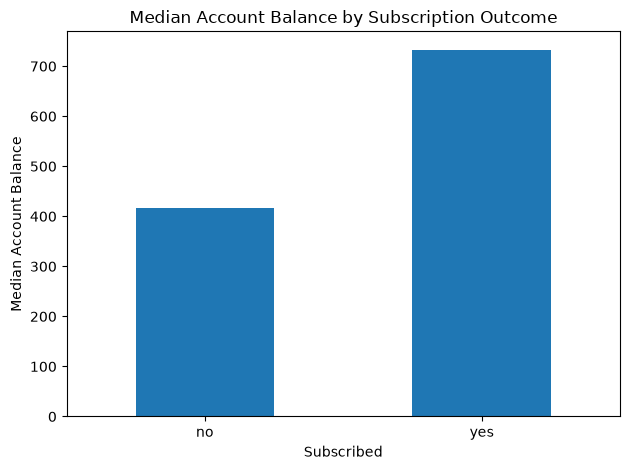

In [45]:
df.groupby("y")["balance"].median().plot(kind="bar")

plt.title("Median Account Balance by Subscription Outcome")
plt.xlabel("Subscribed")
plt.ylabel("Median Account Balance")
plt.gca().yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Business Interpretation

Comparing both the mean and median is useful because financial balance data can contain large outliers.

The median provides a more robust representation of the typical customer when extreme account balances are present.

## 6. Housing Loan Status and Subscription

Customers with existing housing loans may have different financial priorities than customers without housing loans. This comparison examines whether subscription behavior differs between these groups.

In [46]:
housing_subscription = (
    df.groupby("housing")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
)

housing_subscription

housing
no     16.702355
yes     7.699960
Name: y, dtype: float64

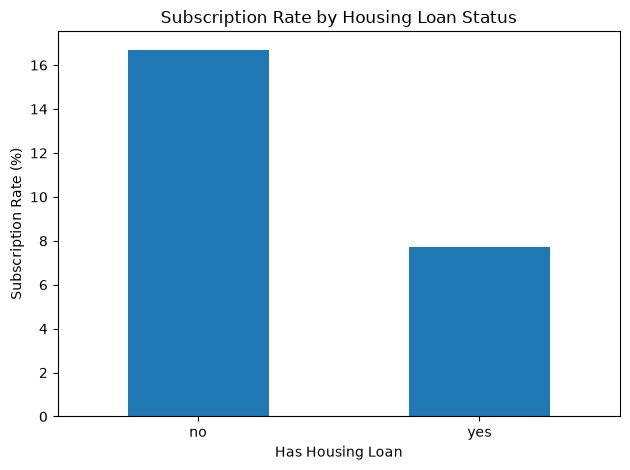

In [47]:
housing_subscription.plot(kind="bar")

plt.title("Subscription Rate by Housing Loan Status")
plt.xlabel("Has Housing Loan")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 7. Personal Loan Status and Subscription

Existing debt obligations may influence a customer's willingness or ability to subscribe to another financial product.

In [48]:
loan_subscription = (
    df.groupby("loan")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
)

loan_subscription

loan
no     12.655727
yes     6.681391
Name: y, dtype: float64

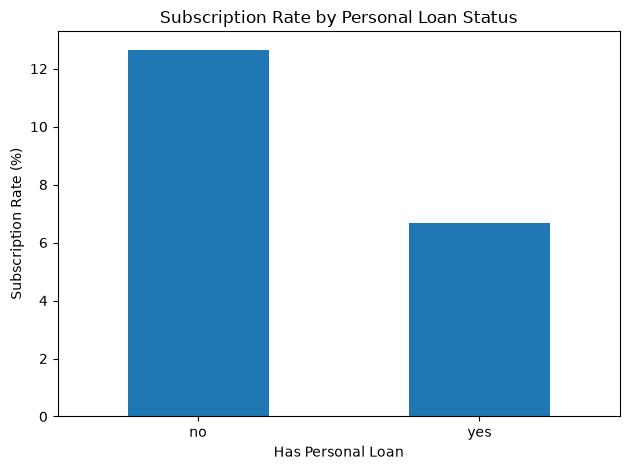

In [49]:
loan_subscription.plot(kind="bar")

plt.title("Subscription Rate by Personal Loan Status")
plt.xlabel("Has Personal Loan")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 8. Contact Method and Campaign Response

This comparison examines whether campaign response varies according to the communication channel used to contact the customer.

In [50]:
contact_subscription = (
    df.groupby("contact")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .sort_values(ascending=False)
)

contact_subscription

contact
cellular     14.918900
telephone    13.420509
unknown       4.070661
Name: y, dtype: float64

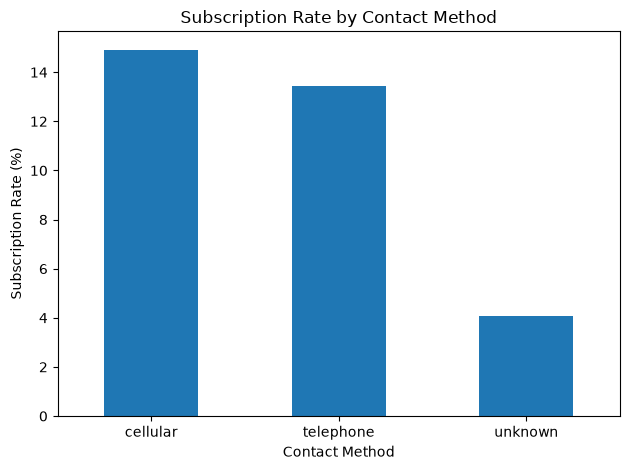

In [51]:
contact_subscription.plot(kind="bar")

plt.title("Subscription Rate by Contact Method")
plt.xlabel("Contact Method")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 9. Campaign Contact Frequency

Repeatedly contacting a customer does not necessarily produce better results. This section examines the relationship between the number of contacts during the campaign and subscription behavior.

In [52]:
campaign_comparison = df.groupby("y")["campaign"].agg(
    ["count", "mean", "median"]
)

campaign_comparison

,count,mean,median
y,,,
no,39922,2.846350,2.0
yes,5289,2.141047,2.0


### Business Interpretation

Campaign frequency should be evaluated as both a marketing-performance and customer-experience issue.

If additional contacts are associated with diminishing response rates, the bank may benefit from more selective customer targeting rather than simply increasing outreach volume.

## 10. Previous Campaign Outcome

A customer's response to a previous marketing campaign may contain useful information about future campaign response.

In [53]:
previous_outcome = pd.crosstab(
    df["poutcome"],
    df["y"],
    normalize="index"
) * 100

previous_outcome.round(2)

y,no,yes
poutcome,,
failure,87.39,12.61
other,83.32,16.68
success,35.27,64.73
unknown,90.84,9.16


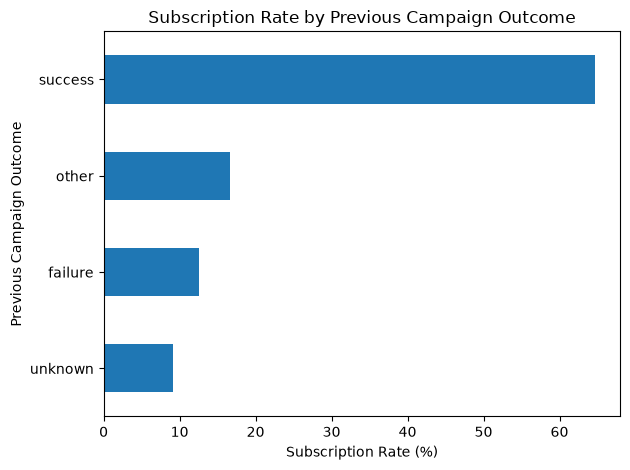

In [54]:
previous_outcome["yes"].sort_values().plot(kind="barh")

plt.title("Subscription Rate by Previous Campaign Outcome")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Previous Campaign Outcome")
plt.tight_layout()
plt.show()

## 11. Multi-Variable Customer Segmentation

Single-variable comparisons can hide important relationships between customer characteristics. This section combines variables to investigate how customer segments differ in campaign response.

In [55]:
job_housing_analysis = (
    df.groupby(["job", "housing"])["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .unstack()
)

job_housing_analysis.round(2)

housing,no,yes
job,,
admin.,17.30,9.02
blue-collar,10.17,6.17
entrepreneur,11.33,6.10
housemaid,10.10,6.03
management,18.20,9.21
retired,26.17,10.59
self-employed,14.62,8.89
services,13.26,6.69
student,35.85,8.84


In [56]:
age_housing_analysis = (
    df.groupby(["age_group", "housing"], observed=False)["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .unstack()
)

age_housing_analysis.round(2)

housing,no,yes
age_group,,
Under 30,28.51,9.56
30-39,15.15,7.86
40-49,12.15,6.96
50-59,12.03,5.87
60-69,31.90,21.18
70+,41.51,83.33


### Business Interpretation

The multi-variable comparisons demonstrate why customer segmentation should consider combinations of characteristics rather than relying on a single attribute.

Two customers with the same occupation or age group may have different financial obligations and therefore different campaign responses. This supports a more targeted approach to customer outreach.

## 12. Key Takeaways

This comparative analysis extends the initial exploratory analysis by examining differences in term deposit subscription behavior across customer and campaign characteristics.

Key analytical themes include:

- Subscription behavior varies across customer segments.
- Financial characteristics such as account balance and existing loan obligations provide additional context for customer behavior.
- Campaign characteristics, including contact method and contact frequency, may influence response patterns.
- Previous campaign behavior may contain useful information for identifying customers who are more likely to respond.
- Multi-variable segmentation provides more context than evaluating customer characteristics independently.

These findings are descriptive rather than causal. They identify patterns and relationships in historical campaign data but do not establish that any individual characteristic causes a customer to subscribe.

The next stages of the project will use SQL for business-focused querying and machine learning to evaluate whether these customer and campaign characteristics can be used to predict subscription outcomes.